# **Mini-Proyecto 2 Bioinformática: Análisis de datos (DM y ML)**

*Conjunto de datos: Breast Cancer Wisconsin (Diagnostic) — WDBC*

Alumna: Candela Ahumada Horgan

## **1- Dataset y objetivo**

Elegí el dataset **Breast Cancer Wisconsin (Diagnostic)**, que lo descargué de la página de UCI:
https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic

Los datos salen de imágenes de una punción con aguja fina (PAAF) de un nódulo de mama. En cada imagen se midieron características de los núcleos de las células (tamaño, forma, textura, etc.).

**Objetivo:** usar estas mediciones para predecir si el tumor es **benigno (B) o maligno (M)**, y ver cuáles son las características que más sirven para diferenciarlos.

## **2- Abrir el conjunto de datos**

Primero hay que subir el archivo `wdbc.data` al colab. El archivo no tiene encabezado, entonces le pongo yo los nombres a las columnas según lo que dice el archivo `wdbc.names`.

In [ ]:
import pandas as pd   # Importación de la biblioteca pandas para poder usar sus funciones
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# 10 características que se miden para cada núcleo celular
caracteristicas = ['radius', 'texture', 'perimeter', 'area', 'smoothness',
                   'compactness', 'concavity', 'concave_points', 'symmetry', 'fractal_dimension']

# Para cada una se calcula la media (mean), el error estándar (se) y el peor valor (worst)
column_names = (['ID', 'diagnosis']
                + [c + '_mean' for c in caracteristicas]
                + [c + '_se' for c in caracteristicas]
                + [c + '_worst' for c in caracteristicas])  # Lista de nombres

datos = pd.read_csv('wdbc.data', header=None, names=column_names) # leer el dataframe
datos # imprimir el dataframe en pantalla

,ID,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


**¿Cuántas columnas hay? Describir cada una de ellas.**

In [ ]:
datos.shape

(569, 32)

In [ ]:
len(column_names)

32

In [ ]:
column_names

['ID',
 'diagnosis',
 'radius_mean',
 'texture_mean',
 'perimeter_mean',
 'area_mean',
 'smoothness_mean',
 'compactness_mean',
 'concavity_mean',
 'concave_points_mean',
 'symmetry_mean',
 'fractal_dimension_mean',
 'radius_se',
 'texture_se',
 'perimeter_se',
 'area_se',
 'smoothness_se',
 'compactness_se',
 'concavity_se',
 'concave_points_se',
 'symmetry_se',
 'fractal_dimension_se',
 'radius_worst',
 'texture_worst',
 'perimeter_worst',
 'area_worst',
 'smoothness_worst',
 'compactness_worst',
 'concavity_worst',
 'concave_points_worst',
 'symmetry_worst',
 'fractal_dimension_worst']

**Respuesta:** hay **32 columnas**:

- **`ID`**: es el número de identificación de cada muestra. No es una medición, es solo un código.
- **`diagnosis`**: el diagnóstico, M (maligno) o B (benigno). **Esta es la variable objetivo**, la que queremos predecir.
- **Las otras 30 columnas** son las mediciones de los núcleos. En realidad son 10 características, y de cada una hay 3 versiones:
  - `_mean`: el promedio de todos los núcleos de la imagen
  - `_se`: el error estándar
  - `_worst`: el "peor" valor (el promedio de los 3 valores más grandes)

Las 10 características son:

| Característica | Qué mide |
|---|---|
| radius | Radio del núcleo (distancia promedio del centro al borde) |
| texture | Textura (qué tanto varían los tonos de gris) |
| perimeter | Perímetro del núcleo |
| area | Área del núcleo |
| smoothness | Suavidad (qué tanto varía el radio a lo largo del borde) |
| compactness | Compacidad (perímetro² / área − 1) |
| concavity | Concavidad (qué tan profundas son las partes cóncavas del borde) |
| concave_points | Puntos cóncavos (cuántas partes cóncavas tiene el borde) |
| symmetry | Simetría del núcleo |
| fractal_dimension | Dimensión fractal (qué tan "irregular" o complejo es el borde) |

**¿Cuántos datos tiene el conjunto de datos?**

In [ ]:
len(datos)

569

**Respuesta:** con `datos.shape` da `(569, 32)`: el primer número son las filas y el segundo las columnas. Y `len(datos)` también da **569**. O sea que el conjunto tiene **569 muestras** (filas), cada una con 32 columnas.

**¿Cuál es la variable objetivo, y cuáles y cuántas son las clases que toma la misma?**

In [ ]:
datos['diagnosis'].unique()

array(['M', 'B'], dtype=object)

**Respuesta:** la variable objetivo es **`diagnosis`**. Tiene **2 clases**: **M** (maligno) y **B** (benigno). O sea que es un problema de clasificación binaria.

**¿Cuántos features numéricos y categóricos tiene?**

In [ ]:
datos.dtypes

,0
ID,int64
diagnosis,object
radius_mean,float64
texture_mean,float64
perimeter_mean,float64
area_mean,float64
smoothness_mean,float64
compactness_mean,float64
concavity_mean,float64
concave_points_mean,float64


In [ ]:
datos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   ID                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave_points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

**Respuesta:** con `dtypes` e `info()` se ve que el archivo tiene 31 columnas numéricas (30 `float64` y 1 `int64`, que es ID) y 1 categórica: diagnosis, que aparece como `object` porque tiene letras (M o B).

Pero diagnosis es la variable objetivo, o sea lo que queremos predecir, así que no cuenta como feature. Y ID es numérica, pero no sirve como feature porque es solo un código de identificación.

Entonces, como features tenemos 30 numéricos y 0 categóricos.

**De las features numéricas, ¿cuáles son sus mínimos y máximos?**

In [ ]:
# Separar solo las 30 features (sin ID ni diagnosis)
x = datos.iloc[:, 2:].values

# Crear un DataFrame con las features y sus nombres
df = pd.DataFrame(x, columns=column_names[2:])

# Ver el resumen estadístico
df.describe()

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


**Respuesta:** los mínimos y máximos de cada feature se observan en la tabla de arriba, en las filas `'min'` y `'max'`

**De las features categóricas, ¿cuántos valores únicos tienen?**

In [ ]:
datos['diagnosis'].unique()

array(['M', 'B'], dtype=object)

In [ ]:
len(datos['diagnosis'].unique())

2

**Respuesta:** no tenemos features categóricos. La única columna categórica es `diagnosis` (la variable objetivo), y tiene **2 valores únicos**: M y B.

## **3- Preparación de los datos**

**¿Hay valores faltantes? ¿Cuántos?**

In [ ]:
# En la columna Non-Null Count se ve cuántos datos NO faltantes tiene cada columna
datos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   ID                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave_points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

**Si decidimos eliminar las filas con valores faltantes, ¿cuántas eliminaríamos?**

**Respuesta:** en `info()` todas las columnas tienen **569 non-null**, que es igual al total de filas. Eso quiere decir que **no hay ningún valor faltante** (también lo dice el archivo `wdbc.names`: *Missing attribute values: none* (en la fila numero 138)). Por eso, si eliminamos las filas con faltantes, **no se eliminaría ninguna**.

**Pasar las variables categóricas a números con LabelEncoder**

Como no hay features categóricos, lo único que hay que pasar a números son las clases (`diagnosis`). Lo hago con `LabelEncoder`.

In [ ]:
from sklearn.preprocessing import LabelEncoder

# Crear una instancia de LabelEncoder
label_encoder = LabelEncoder()

# Ajustar el codificador y transformar las etiquetas en valores numéricos
datos['diagnosis'] = label_encoder.fit_transform(datos['diagnosis'])

# Imprimir las correspondencias entre etiquetas originales y valores numéricos
label_mapping = dict(zip(label_encoder.classes_, range(len(label_encoder.classes_))))
print("Correspondencia entre etiquetas originales y valores numéricos:")
print(label_mapping)

Correspondencia entre etiquetas originales y valores numéricos:
{'B': 0, 'M': 1}


Quedó **B (benigno) = 0** y **M (maligno) = 1**. También saco la columna `ID`, porque es solo un código y no aporta nada para clasificar.

In [ ]:
datos_limpios = datos.drop(columns=['ID'])
datos_limpios

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,1,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,1,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,1,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,1,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


In [ ]:
# Guarda el DataFrame limpio en un archivo .txt
datos_limpios.to_csv('datos_limpios.txt', index=False)

**¿Las clases están balanceadas? ¿Cuántos datos tiene cada una de ellas?**

In [ ]:
# Obtener las frecuencias de clases
clases_total = datos_limpios['diagnosis'].value_counts()
print(clases_total)

# Calcular el total de frecuencias
total_frecuencias = clases_total.sum()
print(f'Total {total_frecuencias}')

# Porcentaje de cada clase
print((clases_total / total_frecuencias * 100).round(2))

diagnosis
0    357
1    212
Name: count, dtype: int64
Total 569
diagnosis
0    62.74
1    37.26
Name: count, dtype: float64


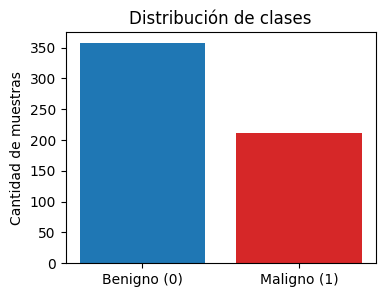

In [ ]:
plt.figure(figsize=(4, 3))
plt.bar(['Benigno (0)', 'Maligno (1)'], clases_total.sort_index().values, color=['tab:blue', 'tab:red'])
plt.ylabel('Cantidad de muestras')
plt.title('Distribución de clases')
plt.show()

**Respuesta:** hay **357 benignos (62,7 %)** y **212 malignos (37,3 %)**. No están perfectamente balanceadas: hay más benignos que malignos (casi el doble). Pero no es un desbalance muy grande, así que se puede trabajar así nomás.

Igual hay que tenerlo en cuenta cuando miremos las matrices de confusión, porque lo más grave sería que el modelo diga "benigno" cuando en realidad es maligno.

## **4- Visualización y reducción de la dimensionalidad**

**¿Cuántas dimensiones habría en el caso que uno quisiera utilizar directamente a todos los features para graficar?**

**Respuesta:** habría **30 dimensiones**, una por cada feature. Eso es imposible de graficar, por eso usamos PCA para llevar los datos a 2 dimensiones.

**¿Las features están todas medidas con las mismas unidades?**

**Respuesta:** **no**. Hay medidas de longitud (radius, perimeter), de área (area), de tonos de gris (texture) y otras que no tienen unidades (smoothness, compactness, concavity, symmetry, fractal_dimension). Por eso los valores están en escalas tan distintas.

**Separar los datos de las clases: guardar en 'X' las features y en 'y' las etiquetas (clases)**

In [ ]:
# separar las características X y las etiquetas y
X = datos_limpios.iloc[:, 1:].values   # de la columna 2 en adelante: los 30 features
y = datos_limpios.iloc[:, 0].values    # la primera columna: diagnosis (las clases)

feature_names = datos_limpios.columns[1:].tolist()

In [ ]:
X

array([[1.799e+01, 1.038e+01, 1.228e+02, ..., 2.654e-01, 4.601e-01,
        1.189e-01],
       [2.057e+01, 1.777e+01, 1.329e+02, ..., 1.860e-01, 2.750e-01,
        8.902e-02],
       [1.969e+01, 2.125e+01, 1.300e+02, ..., 2.430e-01, 3.613e-01,
        8.758e-02],
       ...,
       [1.660e+01, 2.808e+01, 1.083e+02, ..., 1.418e-01, 2.218e-01,
        7.820e-02],
       [2.060e+01, 2.933e+01, 1.401e+02, ..., 2.650e-01, 4.087e-01,
        1.240e-01],
       [7.760e+00, 2.454e+01, 4.792e+01, ..., 0.000e+00, 2.871e-01,
        7.039e-02]])

In [ ]:
y

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1,
       1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1,
       0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1,
       0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1,
       1, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0,
       0, 1, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1,
       1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1,
       0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0,
       0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1,

**Normalizar los datos (features) usando MinMaxScaler()**

In [ ]:
from sklearn.preprocessing import MinMaxScaler

# Crear un objeto MinMaxScaler
scaler = MinMaxScaler()

# Normalizar los datos
X_normalizado = scaler.fit_transform(X)

# Convertirlo a un DataFrame para mejor visualización
X_normalizado_df = pd.DataFrame(X_normalizado, columns=feature_names)
print(X_normalizado_df)

     radius_mean  texture_mean  perimeter_mean  area_mean  smoothness_mean  \
0       0.521037      0.022658        0.545989   0.363733         0.593753   
1       0.643144      0.272574        0.615783   0.501591         0.289880   
2       0.601496      0.390260        0.595743   0.449417         0.514309   
3       0.210090      0.360839        0.233501   0.102906         0.811321   
4       0.629893      0.156578        0.630986   0.489290         0.430351   
..           ...           ...             ...        ...              ...   
564     0.690000      0.428813        0.678668   0.566490         0.526948   
565     0.622320      0.626987        0.604036   0.474019         0.407782   
566     0.455251      0.621238        0.445788   0.303118         0.288165   
567     0.644564      0.663510        0.665538   0.475716         0.588336   
568     0.036869      0.501522        0.028540   0.015907         0.000000   

     compactness_mean  concavity_mean  concave_points_mean  sym

In [ ]:
# Ver el resumen estadístico con los datos normalizados
summary = X_normalizado_df.describe()
print(summary)

       radius_mean  texture_mean  perimeter_mean   area_mean  smoothness_mean  \
count   569.000000    569.000000      569.000000  569.000000       569.000000   
mean      0.338222      0.323965        0.332935    0.216920         0.394785   
std       0.166787      0.145453        0.167915    0.149274         0.126967   
min       0.000000      0.000000        0.000000    0.000000         0.000000   
25%       0.223342      0.218465        0.216847    0.117413         0.304595   
50%       0.302381      0.308759        0.293345    0.172895         0.390358   
75%       0.416442      0.408860        0.416765    0.271135         0.475490   
max       1.000000      1.000000        1.000000    1.000000         1.000000   

       compactness_mean  concavity_mean  concave_points_mean  symmetry_mean  \
count        569.000000      569.000000           569.000000     569.000000   
mean           0.260601        0.208058             0.243137       0.379605   
std            0.161992        0.

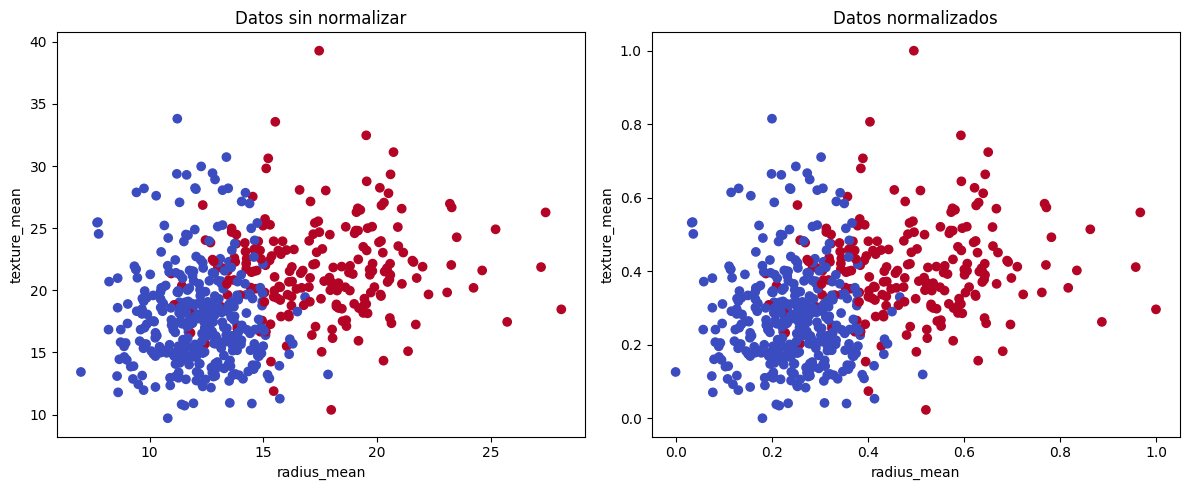

In [ ]:
# Visualizar los datos usando solo dos características antes y después de normalizar
plt.figure(figsize=(12, 5))
plt.subplot(121)
# Visualizar los datos usando solo dos características antes y después de normalizar
# Columna 0 = radius_mean (eje x) y columna 1 = texture_mean (eje y)
# Azul = benigno (0), rojo = maligno (1)
# Los dos gráficos muestran la misma nube de puntos: MinMaxScaler no cambia la forma de los datos,
# solo lleva todas las variables a la misma escala (de 0 a 1)
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm')
plt.title("Datos sin normalizar")
plt.xlabel(feature_names[0])
plt.ylabel(feature_names[1])

plt.subplot(122)
plt.scatter(X_normalizado[:, 0], X_normalizado[:, 1], c=y, cmap='coolwarm')
plt.title("Datos normalizados")
plt.xlabel(feature_names[0])
plt.ylabel(feature_names[1])

plt.tight_layout()
plt.show()

**¿Por qué es importante normalizar los datos antes de aplicar PCA?**

**Respuesta:** porque PCA busca las direcciones de **máxima varianza**, y la varianza depende de la escala de cada variable. Si no se normaliza, las variables con valores grandes (como `area_worst` o `area_mean`, que llegan a miles) tienen una varianza muchísimo mayor solo por su magnitud y **dominan** las componentes principales, aunque no sean las más importantes. Al normalizar con MinMaxScaler todas las features quedan en el rango [0, 1], en la misma escala independientemente de sus unidades, y así ninguna domina a las otras.

**Aplicar PCA para poder visualizar los datos en una gráfica 2D**

In [ ]:
from sklearn.decomposition import PCA

# Aplicar PCA
pca = PCA()
X_pca = pca.fit_transform(X_normalizado)

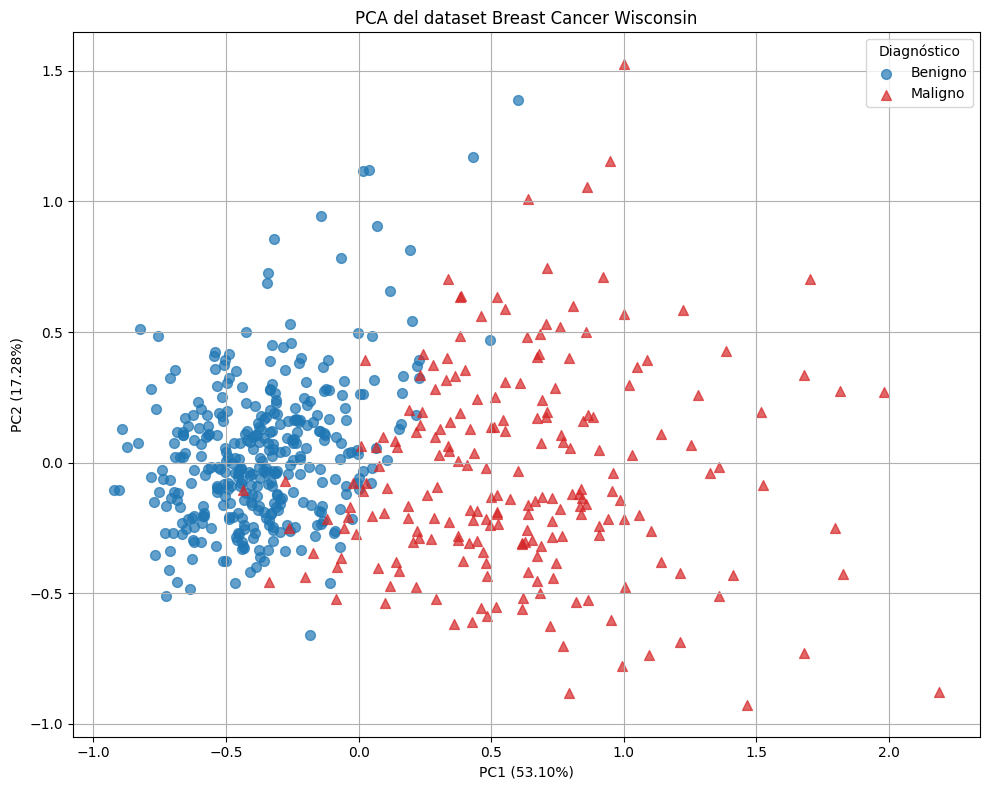

In [ ]:
# Etiquetas para el gráfico
diagnostico = np.where(y == 1, 'Maligno', 'Benigno')

# DataFrame con los resultados del PCA
pca_data = pd.DataFrame(X_pca[:, :2], columns=['PC1', 'PC2'])
pca_data['diagnosis'] = diagnostico

colores = {'Benigno': 'tab:blue', 'Maligno': 'tab:red'}
markers = {'Benigno': 'o', 'Maligno': '^'}

plt.figure(figsize=(10, 8))
for tipo, grupo in pca_data.groupby('diagnosis'):
    plt.scatter(grupo['PC1'], grupo['PC2'], color=colores[tipo], marker=markers[tipo],
                label=tipo, alpha=0.7, s=50)

plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.2%})')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.2%})')
plt.title('PCA del dataset Breast Cancer Wisconsin')
plt.legend(title='Diagnóstico', loc='best')
plt.grid(True)
plt.tight_layout()
plt.show()

**Verificar la cantidad de varianza que están explicando los primeros componentes principales (PC1 + PC2)**

In [ ]:
# Crear un DataFrame con los resultados del PCA
pca_df = pd.DataFrame(data = {
    'standard_deviation': np.sqrt(pca.explained_variance_),
    'proportion_of_variance': pca.explained_variance_ratio_,
    'cumulative_proportion': np.cumsum(pca.explained_variance_ratio_)
})

# Añadir una columna para los componentes principales
pca_df.index = [f'PC{i}' for i in range(1, len(pca_df) + 1)]
pca_df.index.name = 'component'

print("Resumen de PCA:")
print(pca_df)
print("\n")
print(f"Varianza explicada por PC1 + PC2: {pca.explained_variance_ratio_[:2].sum():.2%}")

Resumen de PCA:
           standard_deviation  proportion_of_variance  cumulative_proportion
component                                                                   
PC1                  0.575616                0.530977               0.530977
PC2                  0.328406                0.172835               0.703812
PC3                  0.210700                0.071144               0.774956
PC4                  0.200017                0.064113               0.839069
PC5                  0.159679                0.040861               0.879930
PC6                  0.138443                0.030715               0.910644
PC7                  0.099320                0.015808               0.926453
PC8                  0.086226                0.011915               0.938368
PC9                  0.078536                0.009884               0.948252
PC10                 0.076809                0.009454               0.957706
PC11                 0.072803                0.008494       

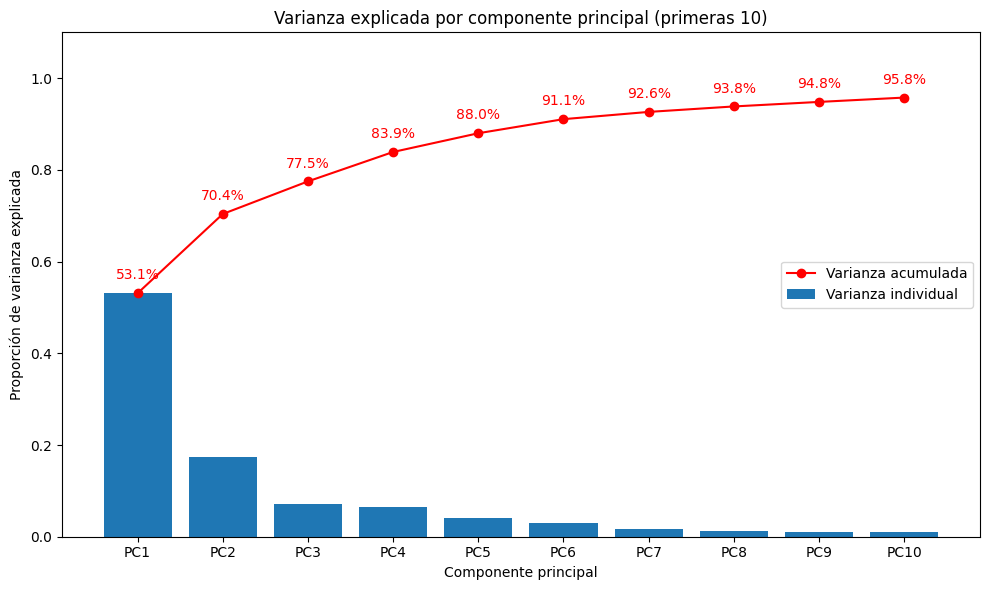

In [ ]:
var = pca.explained_variance_ratio_[:10]
acum = np.cumsum(pca.explained_variance_ratio_)[:10]
pcs = np.arange(1, len(var) + 1)

plt.figure(figsize=(10, 6))
plt.bar(pcs, var, label='Varianza individual')
plt.plot(pcs, acum, marker='o', color='red', label='Varianza acumulada')

# Etiquetar el % acumulado sobre cada punto
for pc, a in zip(pcs, acum):
    plt.text(pc, a + 0.03, f'{a:.1%}', ha='center', color='red')

plt.xticks(pcs, [f'PC{i}' for i in pcs])
plt.ylim(0, 1.1)
plt.xlabel('Componente principal')
plt.ylabel('Proporción de varianza explicada')
plt.title('Varianza explicada por componente principal (primeras 10)')
plt.legend(loc='center right')
plt.tight_layout()
plt.show()

**Respuesta:** PC1 explica el **53,1 %** de la varianza y PC2 el **17,3 %**, así que entre las dos (**PC1 + PC2**) explican el **70,4 %**.

Es menos que en el ejemplo de Iris de la práctica (más del 95 %), pero es lógico porque acá tenemos 30 variables en vez de 4. Aun así, en el gráfico del PCA ya se ve que **benignos y malignos se separan bastante bien sobre el eje de PC1**: los benignos quedan a la izquierda y los malignos a la derecha, con una zona en el medio donde se mezclan un poco.

**Obtener los vectores de carga**

In [ ]:
# Obtener los vectores de carga (loadings)
loadings = pca.components_.T

# Crear un DataFrame con los loadings
loadings_df = pd.DataFrame(loadings, columns=[f'PC{i}' for i in range(1, len(loadings[0]) + 1)],
                           index=feature_names)

print("Vectores de carga (Loadings) de PC1 y PC2:")
print(loadings_df[['PC1', 'PC2']])

Vectores de carga (Loadings) de PC1 y PC2:
                              PC1       PC2
radius_mean              0.242676 -0.261317
texture_mean             0.096479 -0.059058
perimeter_mean           0.252550 -0.238590
area_mean                0.216495 -0.231107
smoothness_mean          0.109695  0.199884
compactness_mean         0.240398  0.213915
concavity_mean           0.301914  0.113811
concave_points_mean      0.322475 -0.008312
symmetry_mean            0.111432  0.211115
fractal_dimension_mean   0.043298  0.406392
radius_se                0.121761 -0.066899
texture_se              -0.000039  0.060011
perimeter_se             0.118581 -0.051416
area_se                  0.103569 -0.082963
smoothness_se           -0.004684  0.135596
compactness_se           0.129320  0.222353
concavity_se             0.065681  0.102793
concave_points_se        0.124746  0.105647
symmetry_se              0.014490  0.140475
fractal_dimension_se     0.045501  0.171995
radius_worst             0.259387

In [ ]:
# Features ordenadas por el valor absoluto de su carga en PC1 y en PC2
print("Top 5 features en PC1:")
print(loadings_df['PC1'].abs().sort_values(ascending=False).head(5))
print("\nTop 5 features en PC2:")
print(loadings_df['PC2'].abs().sort_values(ascending=False).head(5))

Top 5 features en PC1:
concave_points_worst    0.371065
concave_points_mean     0.322475
concavity_mean          0.301914
perimeter_worst         0.260708
radius_worst            0.259387
Name: PC1, dtype: float64

Top 5 features en PC2:
fractal_dimension_mean     0.406392
radius_mean                0.261317
fractal_dimension_worst    0.258092
radius_worst               0.244282
perimeter_mean             0.238590
Name: PC2, dtype: float64


**En base a los vectores de carga, ¿cuál es la feature más relevante para PC1? ¿Y para PC2?**

**Respuesta:**
- En **PC1** la feature más relevante es **`concave_points_worst`** (carga 0,37), y le siguen `concave_points_mean` y `concavity_mean`. O sea que PC1 tiene que ver sobre todo con **qué tan cóncavo e irregular es el borde del núcleo** (y también con el tamaño).
- En **PC2** la feature más relevante es **`fractal_dimension_mean`** (carga 0,41).

**Hacer un biplot**

Para que se pueda leer, en el biplot dibujo solo las 10 flechas de las variables que más pesan en PC1 y PC2 (con las 30 juntas no se entiende nada).

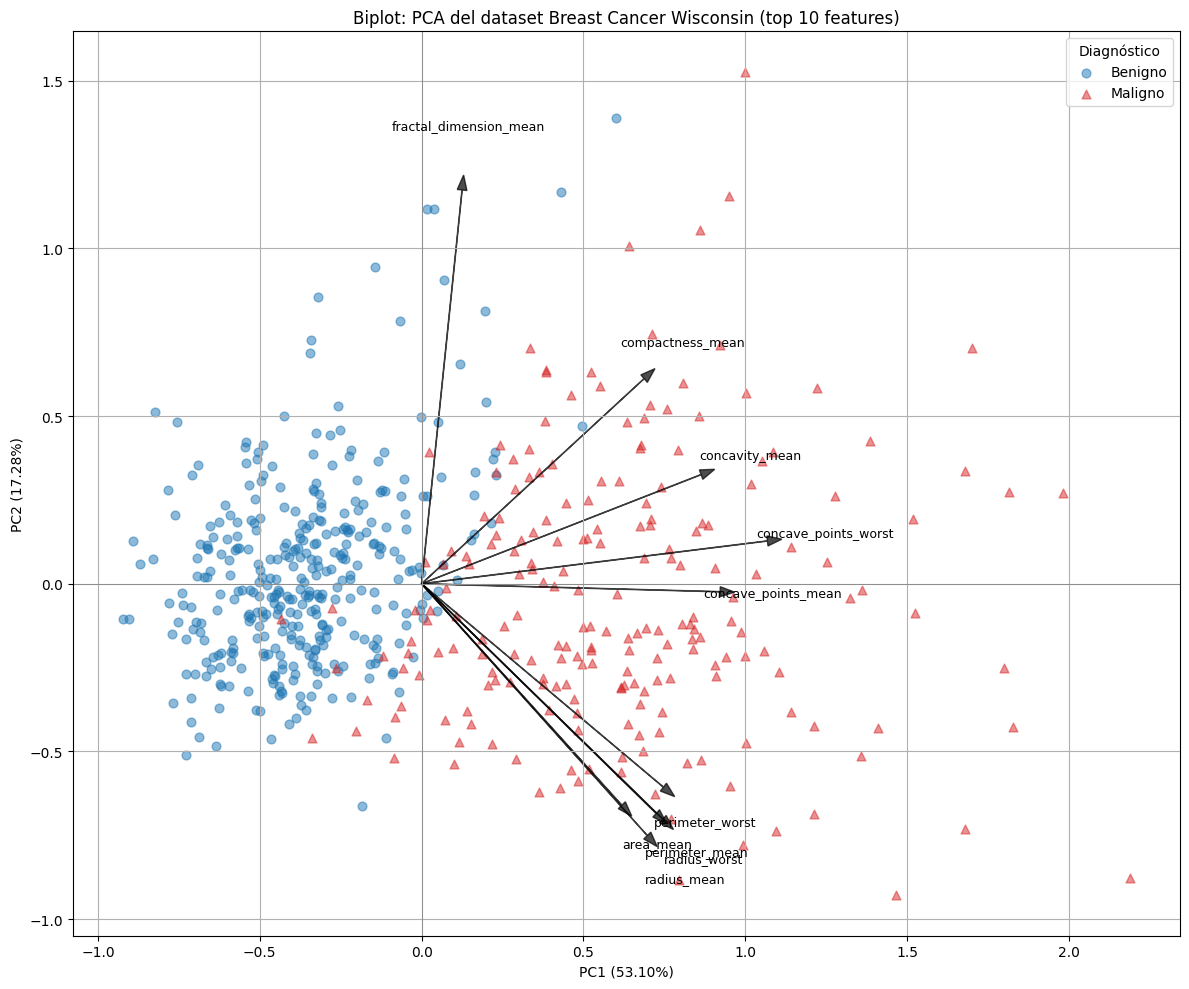

In [ ]:
plt.figure(figsize=(12, 10))

# Puntos
for tipo, grupo in pca_data.groupby('diagnosis'):
    plt.scatter(grupo['PC1'], grupo['PC2'], color=colores[tipo], marker=markers[tipo],
                label=tipo, alpha=0.5, s=40)

# Flechas: solo las k variables que más pesan en el plano PC1-PC2
k = 10
escala = 3     # factor visual para que las flechas se vean junto a los puntos
importancia = np.sqrt(loadings[:, 0]**2 + loadings[:, 1]**2)
top = np.argsort(importancia)[::-1][:k]

for j in top:
    lx, ly = loadings[j, 0], loadings[j, 1]
    plt.arrow(0, 0, lx * escala, ly * escala, color='k', alpha=0.7,
              head_width=0.03, length_includes_head=True)
    plt.text(lx * escala * 1.12, ly * escala * 1.12, feature_names[j],
             color='k', ha='center', va='center', fontsize=9)

plt.axhline(0, color='grey', lw=0.5)
plt.axvline(0, color='grey', lw=0.5)
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.2%})')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.2%})')
plt.title(f'Biplot: PCA del dataset Breast Cancer Wisconsin (top {k} features)')
plt.legend(title='Diagnóstico', loc='best')
plt.grid(True)
plt.tight_layout()
plt.show()

**En base al biplot, ¿cuál es la feature más relevante para PC1? ¿Y para PC2?**

**Respuesta:** en el biplot, la flecha que más se estira hacia la derecha (sobre el eje de **PC1**) es la de **`concave_points_worst`**, así que es la más relevante para PC1. La flecha que más se estira hacia arriba (sobre el eje de **PC2**) es la de **`fractal_dimension_mean`**, así que es la más relevante para PC2. Coincide con lo que dieron los vectores de carga.



## **5- Machine learning**

### *Random forest*

**Verificar (hacer prints) que en 'X' siga teniendo las features y en 'y' las etiquetas (clases)**

In [ ]:
print(f'Forma de X: {X.shape}')    # 569 muestras x 30 features
print(f'Forma de y: {y.shape}')
print('\nPrimera fila de X:')
print(X[0])
print('\nPrimeros 20 valores de y:')
print(y[:20])
print(f'\nClases en y: {np.unique(y)}')

Forma de X: (569, 30)
Forma de y: (569,)

Primera fila de X:
[1.799e+01 1.038e+01 1.228e+02 1.001e+03 1.184e-01 2.776e-01 3.001e-01
 1.471e-01 2.419e-01 7.871e-02 1.095e+00 9.053e-01 8.589e+00 1.534e+02
 6.399e-03 4.904e-02 5.373e-02 1.587e-02 3.003e-02 6.193e-03 2.538e+01
 1.733e+01 1.846e+02 2.019e+03 1.622e-01 6.656e-01 7.119e-01 2.654e-01
 4.601e-01 1.189e-01]

Primeros 20 valores de y:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0]

Clases en y: [0 1]


In [ ]:
X

array([[1.799e+01, 1.038e+01, 1.228e+02, ..., 2.654e-01, 4.601e-01,
        1.189e-01],
       [2.057e+01, 1.777e+01, 1.329e+02, ..., 1.860e-01, 2.750e-01,
        8.902e-02],
       [1.969e+01, 2.125e+01, 1.300e+02, ..., 2.430e-01, 3.613e-01,
        8.758e-02],
       ...,
       [1.660e+01, 2.808e+01, 1.083e+02, ..., 1.418e-01, 2.218e-01,
        7.820e-02],
       [2.060e+01, 2.933e+01, 1.401e+02, ..., 2.650e-01, 4.087e-01,
        1.240e-01],
       [7.760e+00, 2.454e+01, 4.792e+01, ..., 0.000e+00, 2.871e-01,
        7.039e-02]])

In [ ]:
y

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1,
       1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1,
       0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1,
       0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1,
       1, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0,
       0, 1, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1,
       1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1,
       0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0,
       0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1,

Se ve que `X` tiene las 30 features (569 × 30) e `y` tiene las etiquetas 0 y 1. Para Random Forest y árboles de decisión uso los datos **sin normalizar**, igual que en las prácticas, porque los árboles dividen los datos con umbrales en cada variable y no les importa la escala.

**Entrenar un modelo Random Forest habilitando oob_score=True**

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix

# Definir y entrenar el modelo Random Forest con OOB (Out-Of-Bag)
rf_model = RandomForestClassifier(n_estimators=1000, oob_score=True, random_state=0)
rf_model.fit(X, y)

RandomForestClassifier(n_estimators=1000, oob_score=True, random_state=0)

**Obtener e interpretar la precisión OOB**

In [ ]:
# Imprimir un resumen del modelo
print("Resumen del modelo Random Forest:")
print(f"Número de árboles: {rf_model.n_estimators}")
print(f"Precisión OOB: {rf_model.oob_score_:.4f}")
print(f"Error OOB: {1 - rf_model.oob_score_:.4f}")
print(f"Número de características: {rf_model.n_features_in_}")
print(f"Clases: {rf_model.classes_}")

Resumen del modelo Random Forest:
Número de árboles: 1000
Precisión OOB: 0.9666
Error OOB: 0.0334
Número de características: 30
Clases: [0 1]




**Respuesta:** la precisión OOB es **96,6%** (`Precisión OOB: 0.9666`), o sea un error OOB de 3,3 % (`Error OOB: 0.0334`). Esto quiere decir que el modelo clasificó bien **550 de las 569 muestras**, evaluando cada muestra solo con los árboles que no la usaron para entrenar. Es una estimación de qué tan bien funcionaría el modelo con pacientes nuevos: acertaría el diagnóstico en aproximadamente el 97 % de los casos.



**Realizar una matriz de confusión utilizando las predicciones OOB**

In [ ]:
# Obtener las predicciones OOB
oob_predictions = rf_model.oob_decision_function_

# Convertir probabilidades a etiquetas de clase (la clase con la probabilidad más alta)
oob_predicted_labels = rf_model.classes_[np.argmax(oob_predictions, axis=1)]

# Crear la matriz de confusión usando las etiquetas reales y las predicciones OOB
conf_matrix = confusion_matrix(y, oob_predicted_labels, labels=rf_model.classes_)

# Convertir la matriz de confusión a un DataFrame para un formato legible
nombres_clases = ['Benigno (0)', 'Maligno (1)']
conf_matrix_df = pd.DataFrame(conf_matrix, index=nombres_clases, columns=nombres_clases)

# Calcular el error de clase para cada clase
class_error = 1 - np.diag(conf_matrix) / np.sum(conf_matrix, axis=1)

# Imprimir la matriz de confusión con nombres de filas y columnas
print("Matriz de Confusión OOB con Nombres de Clases:")
print(conf_matrix_df)

# Imprimir el error de clase para cada clase
print("\nError de Clase (Class Error) por clase:")
for cls, error in zip(nombres_clases, class_error):
    print(f"Clase {cls}: Error de Clase {error:.4f}")

Matriz de Confusión OOB con Nombres de Clases:
             Benigno (0)  Maligno (1)
Benigno (0)          348            9
Maligno (1)           10          202

Error de Clase (Class Error) por clase:
Clase Benigno (0): Error de Clase 0.0252
Clase Maligno (1): Error de Clase 0.0472


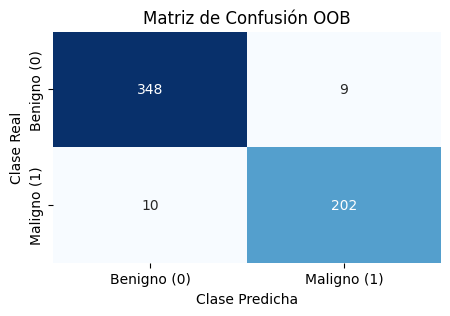

In [ ]:
import seaborn as sns

# Visualizar la matriz de confusión usando un heatmap
plt.figure(figsize=(5, 3))
sns.heatmap(conf_matrix_df, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Matriz de Confusión OOB')
plt.ylabel('Clase Real')
plt.xlabel('Clase Predicha')
plt.show()

En la matriz de confusión se ve que:
- De los 357 **benignos**, 348 los clasificó bien y 9 los confundió con malignos.
- De los 212 **malignos**, 202 los clasificó bien y **10 los confundió con benignos**.

El error por clase es un poco más alto en los malignos (4,7 %) que en los benignos (2,5 %). Tiene sentido porque hay menos malignos, y justamente ese es el error más grave (decir que es benigno cuando es maligno).

**Ordenar las características por importancia**

In [ ]:
# Importancia de las características
feature_importance = rf_model.feature_importances_

# Ordenar las características por importancia en orden descendente
sorted_idx = np.argsort(feature_importance)[::-1]
sorted_feature_importance = feature_importance[sorted_idx]
sorted_feature_names = np.array(feature_names)[sorted_idx]

print('Variables más importantes ordenadas (Random Forest):')
for name, importance in zip(sorted_feature_names, sorted_feature_importance):
    print(f'{name}: {importance:.4f}')

Variables más importantes ordenadas (Random Forest):
perimeter_worst: 0.1316
concave_points_worst: 0.1251
area_worst: 0.1173
radius_worst: 0.1104
concave_points_mean: 0.0903
concavity_mean: 0.0510
perimeter_mean: 0.0486
area_mean: 0.0474
radius_mean: 0.0407
concavity_worst: 0.0353
area_se: 0.0330
texture_worst: 0.0198
compactness_worst: 0.0159
compactness_mean: 0.0145
radius_se: 0.0144
texture_mean: 0.0138
smoothness_worst: 0.0133
perimeter_se: 0.0127
symmetry_worst: 0.0113
fractal_dimension_worst: 0.0069
smoothness_mean: 0.0064
concavity_se: 0.0057
fractal_dimension_se: 0.0053
texture_se: 0.0048
concave_points_se: 0.0048
compactness_se: 0.0044
smoothness_se: 0.0043
symmetry_se: 0.0040
symmetry_mean: 0.0040
fractal_dimension_mean: 0.0033


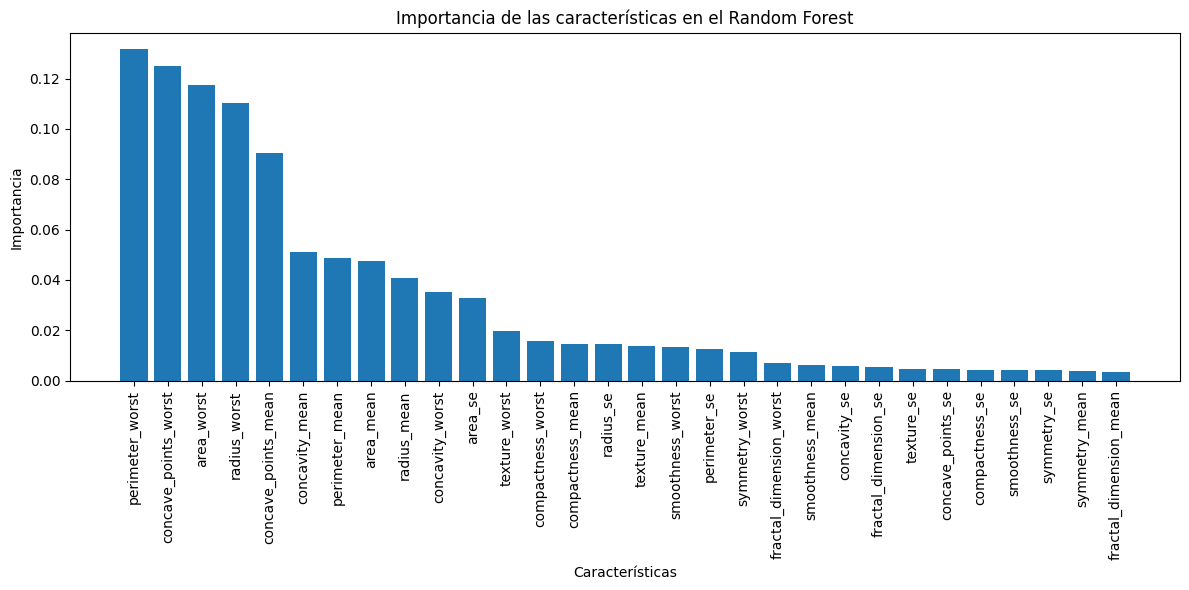

In [ ]:
# Crear el gráfico de barras
plt.figure(figsize=(12, 6))
plt.bar(range(len(sorted_feature_importance)), sorted_feature_importance, align='center')
plt.xticks(range(len(sorted_feature_names)), sorted_feature_names, rotation=90)
plt.xlabel('Características')
plt.ylabel('Importancia')
plt.title('Importancia de las características en el Random Forest')
plt.tight_layout()
plt.show()

Las 5 características más importantes para el Random Forest son: **`perimeter_worst`, `concave_points_worst`, `area_worst`, `radius_worst` y `concave_points_mean`**.

Casi todas son de **tamaño** (perímetro, área, radio) o de **concavidad**, y casi todas en su versión *worst*. Esto coincide con lo que vimos en el PCA, donde esas mismas variables eran las que más pesaban en PC1.

**¿Qué ventajas tiene la evaluación OOB? ¿En qué se diferencia de evaluar el modelo con un conjunto de test independiente?**

**Respuesta:** cuando se arma cada árbol se toma un bootstrap (una muestra al azar con reemplazo, del mismo tamaño que los datos). Así, más o menos **un tercio de las muestras queda afuera** de cada árbol: esas son las muestras OOB. Después cada muestra se predice solo con los árboles que no la usaron para entrenar, y con eso se estima el error.

**Ventajas de la evaluación OOB:**
- **No hace falta separar datos para test**: se entrena con todos los datos y aun así tenemos una estimación del error. Esto sirve mucho cuando hay pocos datos, como acá (569 muestras).
- Sale "gratis" al entrenar el modelo, no hay que entrenarlo de nuevo.
- Es una evaluación honesta, porque cada muestra la evalúan árboles que nunca la vieron.

**Diferencia con un test independiente:** en un test independiente separamos una parte de los datos (por ejemplo el 30 %) que el modelo nunca ve, entrenamos con el resto y evaluamos una sola vez con ese 30 %. El problema es que entrenamos con menos datos y el resultado depende de qué muestras cayeron en el test. En OOB, en cambio, todas las muestras se usan para entrenar y todas se usan para evaluar, el OOB solo se puede usar en modelos que usan bootstrap, como Random Forest.

### *Árboles de decisión*

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score

**Dividir los datos en conjuntos de entrenamiento y prueba**

In [ ]:
# dividir los datos en conjuntos de entrenamiento y prueba
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)

In [ ]:
# Obtener las frecuencias de clases en el conjunto total de entrenamiento
clases_train = pd.Series(y_train).value_counts()
print(clases_train)
# Calcular el total de frecuencias
total_frecuencias = clases_train.sum()
print(f'Total {total_frecuencias}')

0    249
1    149
Name: count, dtype: int64
Total 398


In [ ]:
# Obtener las frecuencias de clases en el conjunto total de test
clases_test = pd.Series(y_test).value_counts()
print(clases_test)
# Calcular el total de frecuencias
total_frecuencias = clases_test.sum()
print(f'Total {total_frecuencias}')

0    108
1     63
Name: count, dtype: int64
Total 171


**Definir y entrenar un modelo de árbol de decisión**

In [ ]:
# definir y entrenar el modelo
clf = DecisionTreeClassifier(criterion="entropy", min_impurity_decrease=0.03, random_state=0, min_samples_leaf=5)
clf.fit(x_train, y_train)

DecisionTreeClassifier(criterion='entropy', min_impurity_decrease=0.03,
                       min_samples_leaf=5, random_state=0)

Uso los mismos parámetros que en la práctica:
- `criterion="entropy"`: usa la entropía para medir qué tan "mezclado" está cada nodo.
- `min_impurity_decrease=0.03`: si dividir un nodo no baja la impureza al menos 0,03, no lo divide.
- `min_samples_leaf=5`: cada hoja tiene que tener por lo menos 5 muestras.

Estos dos últimos sirven para que el árbol no crezca de más y no se sobreajuste.

**Predecir** y **Precisión del modelo**

In [ ]:
# predecir las etiquetas para los datos de prueba y calcular la precisión del modelo
y_pred = clf.predict(x_test)
accuracy = accuracy_score(y_test, y_pred)

# imprimir la precisión del modelo
print("Precisión del modelo: {:.4f}".format(accuracy))

Precisión del modelo: 0.9357


**Imprimir información sobre el árbol:**

*Profundidad

*Cantidad de hojas


In [ ]:
# Imprimir información sobre el árbol
print(f'Profundidad del árbol: {clf.get_depth()}')
print(f'Número de hojas: {clf.get_n_leaves()}')

Profundidad del árbol: 3
Número de hojas: 5


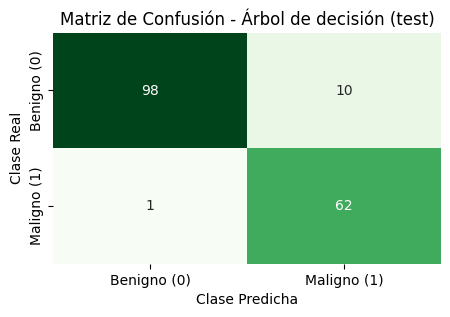

In [ ]:
# Matriz de confusión en el conjunto de test
conf_matrix_dt = confusion_matrix(y_test, y_pred)
conf_matrix_dt_df = pd.DataFrame(conf_matrix_dt, index=nombres_clases, columns=nombres_clases)

plt.figure(figsize=(5, 3))
sns.heatmap(conf_matrix_dt_df, annot=True, fmt='d', cmap='Greens', cbar=False)
plt.title('Matriz de Confusión - Árbol de decisión (test)')
plt.ylabel('Clase Real')
plt.xlabel('Clase Predicha')
plt.show()

**Resultados:**
- **Precisión del modelo:** 0,9357 (93,6 %) en el conjunto de test (171 muestras)
- **Profundidad del árbol:** 3
- **Número de hojas:** 5

Es un árbol muy chiquito y fácil de entender. La primera pregunta que hace es si `concave_points_worst <= 0.142`, y casi todas las muestras que pasan ese valor son malignas. Da un poco menos que el Random Forest (96,7 %), lo cual es esperable porque es un solo árbol contra 1000.

In [ ]:
# Imprimir las características más importantes ordenadas
importances = clf.feature_importances_
sorted_indices = np.argsort(importances)[::-1] # Ordena los índices en orden descendente

print('Variables más importantes ordenadas (Árbol de decisión):')
for idx in sorted_indices:
    feature_name = feature_names[idx]
    importance = importances[idx]
    if importance > 0:
        print(f'{feature_name}: {importance:.4f}')

Variables más importantes ordenadas (Árbol de decisión):
concave_points_worst: 0.7572
perimeter_worst: 0.1965
texture_worst: 0.0463


**Las características más importantes, ¿coinciden con lo observado en Random forest?**

**Respuesta:** **sí, bastante**. El árbol usa solo 3 variables: **`concave_points_worst`** (importancia 0,76), **`perimeter_worst`** (0,20) y `texture_worst` (0,05). Las dos primeras son justo **las dos más importantes del Random Forest** (solo que en el RF el orden está al revés).

La diferencia es que el árbol pone casi toda la importancia en una sola variable y a las demás les da 0, mientras que el Random Forest la reparte entre muchas. Esto pasa porque en el Random Forest cada nodo elige entre un grupo de variables al azar, entonces variables parecidas (radio, perímetro y área miden casi lo mismo) se van turnando.

En resumen, los dos modelos están de acuerdo en que lo que más importa es **el tamaño y la concavidad del núcleo**, igual que lo que mostró el PCA.

**Realizar un plot del árbol entrenado y guardarlo en PDF**

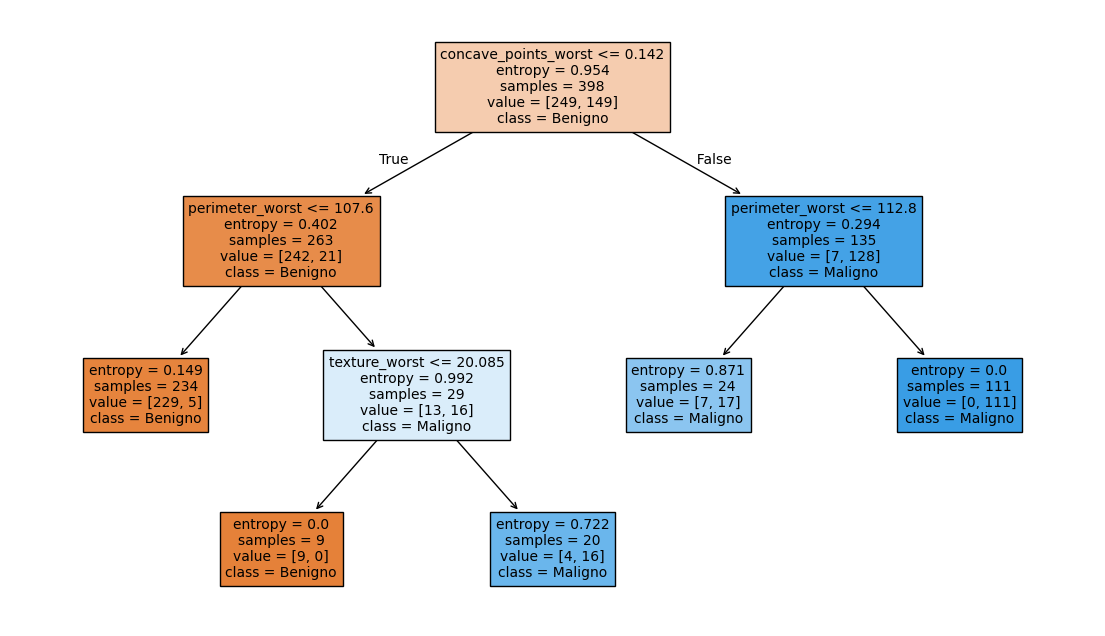

In [ ]:
plt.figure(figsize=(14, 8))
plot_tree(clf, filled=True, feature_names=feature_names, class_names=['Benigno', 'Maligno'], fontsize=10)
plt.savefig('decision_tree.pdf', format='pdf')  # Guarda el árbol en formato PDF
plt.show()  # Muestra el árbol en pantalla

El árbol queda guardado como `decision_tree.pdf`

## **Optativo: SVM y deep learning, y tabla comparativa**

Para SVM y deep learning separo los datos en entrenamiento, validación y test. Acá uso los datos **normalizados** (`X_normalizado`), porque a diferencia de los árboles, el SVM y las redes neuronales sí se ven afectados por la escala de las variables.

### *Máquinas de vectores soporte (SVM)*

In [ ]:
from sklearn.svm import SVC
from sklearn.metrics import classification_report

# Separar datos para entrenamiento y test
X_train, X_test, y_train2, y_test2 = train_test_split(X_normalizado, y, train_size=0.8, test_size=0.2, random_state=42)

# Subdividir el conjunto de entrenamiento en train y val
X_train, X_val, y_train2, y_val = train_test_split(X_train, y_train2, train_size=0.8, test_size=0.2, random_state=42)

print("Tamaño del conjunto de entrenamiento:", len(X_train))
print("Tamaño del conjunto de validación:", len(X_val))
print("Tamaño del conjunto de prueba:", len(X_test))

Tamaño del conjunto de entrenamiento: 364
Tamaño del conjunto de validación: 91
Tamaño del conjunto de prueba: 114


In [ ]:
# Valores de C a evaluar: 11 valores de 0.00001 a 100000 (multiplicando por 10)
# C controla qué tanto se castigan los errores del SVM; después elegimos el que da mejor precisión en validación
valores_C = np.logspace(-5, 5, num=11)
valores_C

array([1.e-05, 1.e-04, 1.e-03, 1.e-02, 1.e-01, 1.e+00, 1.e+01, 1.e+02,
       1.e+03, 1.e+04, 1.e+05])

Con kernel radial:

Mejor valor de C: 1.0
Precisión máxima: 0.967032967032967
Error mínimo en validación: 3.3%


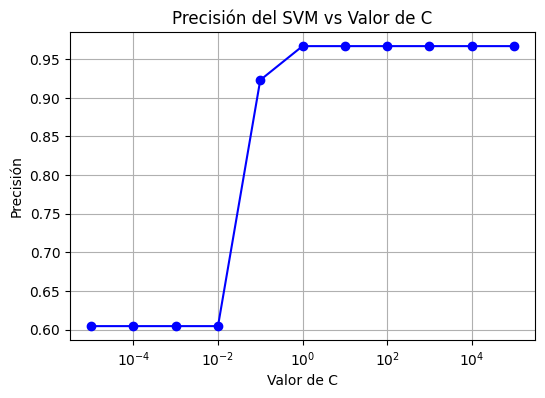


Resultados en el conjunto de prueba:
Precisión en test: 0.9736842105263158
Error en test: 2.63%

Matriz de Confusión:
[[70  1]
 [ 2 41]]

Reporte de Clasificación:
              precision    recall  f1-score   support

     Benigno       0.97      0.99      0.98        71
     Maligno       0.98      0.95      0.96        43

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



In [ ]:
# Inicializar una lista para almacenar las precisiones
precisiones = []

# Bucle sobre los valores de C
for C in valores_C:
    # Entrenar el modelo SVM con el valor actual de C
    modelo_svm = SVC(kernel='rbf', C=C)
    modelo_svm.fit(X_train, y_train2)

    # Realizar predicciones en el conjunto de validación
    predicciones = modelo_svm.predict(X_val)

    # Evaluar el rendimiento del modelo
    precision = accuracy_score(y_val, predicciones)
    precisiones.append(precision)

# Encontrar el valor de C que maximiza la precisión
mejor_C = valores_C[np.argmax(precisiones)]

# Calcular el error mínimo
error_minimo = 1 - max(precisiones)
error_porcentaje = round(error_minimo * 100, 2)

# Imprimir resultados
print(f"Mejor valor de C: {mejor_C}")
print(f"Precisión máxima: {max(precisiones)}")
print(f"Error mínimo en validación: {error_porcentaje}%")

# Gráfico de la precisión en función de C
plt.figure(figsize=(6, 4))
plt.semilogx(valores_C, precisiones, 'b-o')
plt.xlabel('Valor de C')
plt.ylabel('Precisión')
plt.title('Precisión del SVM vs Valor de C')
plt.grid(True)
plt.show()

# Entrenar el modelo SVM final con el mejor valor de C
modelo_svm_final = SVC(kernel='rbf', C=mejor_C)
modelo_svm_final.fit(X_train, y_train2)

# Realizar predicciones en el conjunto de prueba
predicciones_test = modelo_svm_final.predict(X_test)

# Evaluar el rendimiento del modelo en el conjunto de prueba
precision_svm_rbf = accuracy_score(y_test2, predicciones_test)
error_test = 1 - precision_svm_rbf
error_porcentaje_test = round(error_test * 100, 2)

# Imprimir resultados en el conjunto de prueba
print("\nResultados en el conjunto de prueba:")
print(f"Precisión en test: {precision_svm_rbf}")
print(f"Error en test: {error_porcentaje_test}%")

# Crear una matriz de confusión
matriz_confusion = confusion_matrix(y_test2, predicciones_test)
reporte_clasificacion = classification_report(y_test2, predicciones_test, target_names=['Benigno', 'Maligno'])

print("\nMatriz de Confusión:")
print(matriz_confusion)
print("\nReporte de Clasificación:")
print(reporte_clasificacion)

Con kernel polinomial:

Mejor valor de C: 1.0
Precisión máxima: 0.967032967032967
Error mínimo en validación: 3.3%


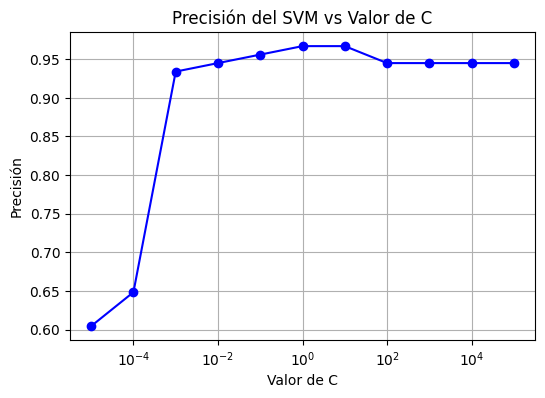


Resultados en el conjunto de prueba:
Precisión en test: 0.9736842105263158
Error en test: 2.63%

Matriz de Confusión:
[[70  1]
 [ 2 41]]

Reporte de Clasificación:
              precision    recall  f1-score   support

     Benigno       0.97      0.99      0.98        71
     Maligno       0.98      0.95      0.96        43

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



In [ ]:
# Inicializar una lista para almacenar las precisiones
precisiones = []

# Bucle sobre los valores de C
for C in valores_C:
    # Entrenar el modelo SVM con el valor actual de C
    modelo_svm = SVC(kernel='poly', C=C)
    modelo_svm.fit(X_train, y_train2)

    # Realizar predicciones en el conjunto de validación
    predicciones = modelo_svm.predict(X_val)

    # Evaluar el rendimiento del modelo
    precision = accuracy_score(y_val, predicciones)
    precisiones.append(precision)

# Encontrar el valor de C que maximiza la precisión
mejor_C = valores_C[np.argmax(precisiones)]

# Calcular el error mínimo
error_minimo = 1 - max(precisiones)
error_porcentaje = round(error_minimo * 100, 2)

# Imprimir resultados
print(f"Mejor valor de C: {mejor_C}")
print(f"Precisión máxima: {max(precisiones)}")
print(f"Error mínimo en validación: {error_porcentaje}%")

# Gráfico de la precisión en función de C
plt.figure(figsize=(6, 4))
plt.semilogx(valores_C, precisiones, 'b-o')
plt.xlabel('Valor de C')
plt.ylabel('Precisión')
plt.title('Precisión del SVM vs Valor de C')
plt.grid(True)
plt.show()

# Entrenar el modelo SVM final con el mejor valor de C
modelo_svm_final = SVC(kernel='poly', C=mejor_C)
modelo_svm_final.fit(X_train, y_train2)

# Realizar predicciones en el conjunto de prueba
predicciones_test = modelo_svm_final.predict(X_test)

# Evaluar el rendimiento del modelo en el conjunto de prueba
precision_svm_poly = accuracy_score(y_test2, predicciones_test)
error_test = 1 - precision_svm_poly
error_porcentaje_test = round(error_test * 100, 2)

# Imprimir resultados en el conjunto de prueba
print("\nResultados en el conjunto de prueba:")
print(f"Precisión en test: {precision_svm_poly}")
print(f"Error en test: {error_porcentaje_test}%")

# Crear una matriz de confusión
matriz_confusion = confusion_matrix(y_test2, predicciones_test)
reporte_clasificacion = classification_report(y_test2, predicciones_test, target_names=['Benigno', 'Maligno'])

print("\nMatriz de Confusión:")
print(matriz_confusion)
print("\nReporte de Clasificación:")
print(reporte_clasificacion)

**Resultados SVM:** con los dos kernels el mejor C fue **C = 1**, y los dos dieron una **precisión en test de 0,9737 (97,4 %)**. Se equivocó solo en 3 de las 114 muestras: 1 benigno que lo dio como maligno y **2 malignos que los dio como benignos**.



### *Redes neuronales profundas (deep learning)*

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Definir la red neuronal
model = models.Sequential()
model.add(layers.Dense(256, activation='relu'))
model.add(layers.BatchNormalization())
model.add(layers.Dropout(0.5))
model.add(layers.Dense(128, activation='relu'))
model.add(layers.BatchNormalization())
model.add(layers.Dropout(0.5))
model.add(layers.Dense(64, activation='relu'))
model.add(layers.BatchNormalization())
model.add(layers.Dense(2, activation='softmax'))  # 2 clases: benigno y maligno

In [ ]:
# Compilar el modelo
model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
              metrics=['accuracy'])

In [ ]:
# Definir hiperparámetros
epocas = 30
batch_size = 32

Epoch 1/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 5s 36ms/step - accuracy: 0.7857 - loss: 0.4863 - val_accuracy: 0.4066 - val_loss: 0.6620
Epoch 2/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8956 - loss: 0.2431 - val_accuracy: 0.4945 - val_loss: 0.6285
Epoch 3/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9451 - loss: 0.1532 - val_accuracy: 0.7253 - val_loss: 0.5386
Epoch 4/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9588 - loss: 0.1366 - val_accuracy: 0.8462 - val_loss: 0.4681
Epoch 5/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9451 - loss: 0.1471 - val_accuracy: 0.9231 - val_loss: 0.4207
Epoch 6/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9698 - loss: 0.1057 - val_accuracy: 0.9560 - val_loss: 0.3725
Epoch 7/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9615 - loss: 0.1054 - val_accuracy: 0.9560 - val_loss: 0.3440
Epoch 8/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9560 - loss: 0.1041 - val_accuracy: 0.9560 - v

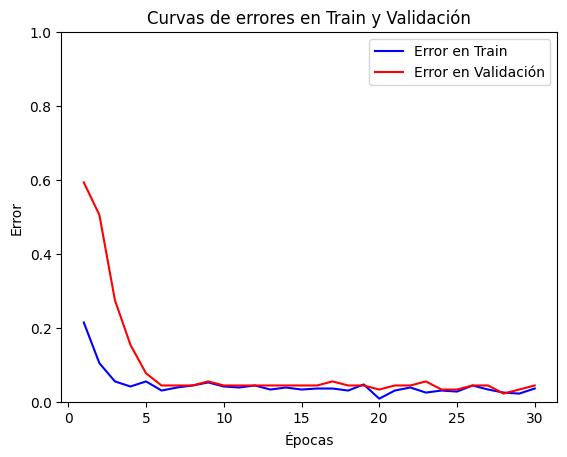

In [ ]:
# Entrenar el modelo y almacenar el historial
history = model.fit(X_train, y_train2, epochs=epocas, batch_size=batch_size, validation_data=(X_val, y_val))

# Graficar error en función de las épocas
# Obtener los valores de accuracy y val_accuracy
train_accuracy = history.history['accuracy']
val_accuracy = history.history['val_accuracy']

# Obtener las curvas de error en train y validación
Error_train = [1 - acc for acc in train_accuracy]
Error_val = [1 - acc for acc in val_accuracy]

# Curvas de error en train y validación
epochs = range(1, len(train_accuracy) + 1)
plt.plot(epochs, Error_train, 'b', label='Error en Train')
plt.plot(epochs, Error_val, 'r', label='Error en Validación')
plt.title('Curvas de errores en Train y Validación')
plt.xlabel('Épocas')
plt.ylabel('Error')
plt.ylim([0, 1])
plt.legend()
plt.show()

In [ ]:
# Evaluar el modelo con los datos de test
test_loss, precision_dl = model.evaluate(X_test, y_test2)

# Imprimir el resultado
print(f'\nPérdida en Test: {test_loss}')
print(f'Precisión en Test: {precision_dl}')

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9649 - loss: 0.1084

Pérdida en Test: 0.10838107019662857
Precisión en Test: 0.9649122953414917


In [ ]:
# Matriz de confusión de la red en test
pred_dl = np.argmax(model.predict(X_test), axis=1)
print("Matriz de Confusión:")
print(confusion_matrix(y_test2, pred_dl))

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
Matriz de Confusión:
[[71  0]
 [ 4 39]]


**Resultados deep learning:** la red dio una **precisión en test de 0,9649 (96,5 %)**, con una pérdida de 0,108. En la matriz de confusión se ve que se equivocó en **4 de las 114 muestras**: clasificó bien a los 71 benignos, pero **4 malignos los dio como benignos** (falsos negativos).

En el gráfico de las curvas, el error de validación arranca alto (cerca de 0,6) porque al principio la red tiene pesos al azar, pero baja muy rápido y para la época 6 ya está en alrededor de 0,05. Desde ahí, las dos curvas (train y validación) quedan prácticamente **pegadas**, con un error de entre 0,03 y 0,05 hasta el final. Como el error de validación no sube ni se separa del de train, **no hay sobreajuste** (para eso sirven el Dropout y el BatchNormalization).

la red arranca con pesos al azar, entonces cada vez que se corre el colab el resultado puede cambiar un poco.

### *Tabla comparativa*

In [ ]:
tabla = pd.DataFrame({
    'Modelo': ['Random Forest (1000 árboles)', 'Árbol de decisión', 'SVM kernel radial',
               'SVM kernel polinomial', 'Red neuronal (deep learning)'],
    'Datos': ['Sin normalizar', 'Sin normalizar', 'Normalizados (MinMax)',
              'Normalizados (MinMax)', 'Normalizados (MinMax)'],
    'Evaluación': ['OOB (569 muestras)', 'Test 30 % (171 muestras)', 'Test 20 % (114 muestras)',
                   'Test 20 % (114 muestras)', 'Test 20 % (114 muestras)'],
    'Precisión': [rf_model.oob_score_, accuracy, precision_svm_rbf, precision_svm_poly, precision_dl]
})
tabla['Error (%)'] = ((1 - tabla['Precisión']) * 100).round(2)
tabla['Precisión'] = tabla['Precisión'].round(4)
tabla

,Modelo,Datos,Evaluación,Precisión,Error (%)
0,Random Forest (1000 árboles),Sin normalizar,OOB (569 muestras),0.9666,3.34
1,Árbol de decisión,Sin normalizar,Test 30 % (171 muestras),0.9357,6.43
2,SVM kernel radial,Normalizados (MinMax),Test 20 % (114 muestras),0.9737,2.63
3,SVM kernel polinomial,Normalizados (MinMax),Test 20 % (114 muestras),0.9737,2.63
4,Red neuronal (deep learning),Normalizados (MinMax),Test 20 % (114 muestras),0.9649,3.51


**Interpretación:** todos los modelos dieron más de **93 %** de precisión. El que mejor anduvo fue el **SVM (97,4 %)**, después el **Random Forest (96,7 %)** y la **red neuronal (96,5 %)**, y el último fue el **árbol de decisión (93,6 %)**, aunque es el más fácil de interpretar.

Igual hay que tener cuidado al comparar, porque no evaluamos todos de la misma forma (el Random Forest con OOB, el árbol con un test de 171 muestras y el resto con un test de 114). Con 114 muestras de test, equivocarse en una sola muestra cambia la precisión casi un 1 %, así que las diferencias entre SVM, Random Forest y la red son muy chiquitas: el SVM se equivocó en 3 muestras y la red en 4.

## **Conclusiones**

- El dataset tiene **569 muestras** y **30 features**, todos numéricos. La variable que queremos predecir es el diagnóstico, que tiene 2 clases: **357 benignos y 212 malignos**. No tiene datos faltantes.
- Las variables tenían escalas muy distintas (por ejemplo, el área llega a miles y otras no pasan de 0,3), así que antes del PCA, el SVM y la red tuvimos que **normalizarlas con MinMaxScaler** para que todas queden entre 0 y 1.
- Con el **PCA** pasamos de 30 dimensiones a 2. Entre PC1 y PC2 explican el **70,4 %** de la varianza, y en el gráfico ya se ve que benignos y malignos se separan bastante sobre PC1.
- El **Random Forest** tuvo una **precisión OOB de 96,7 %** y el **árbol de decisión** un **93,6 %** en test. El árbol anda un poco peor, pero es mucho más fácil de entender: con solo 3 preguntas ya clasifica.
- El PCA, el Random Forest y el árbol coinciden en que las variables que más importan son las de **tamaño** (`perimeter_worst`, `area_worst`, `radius_worst`) y de **concavidad** (`concave_points_worst`) del núcleo.
- En la parte optativa, el **SVM** fue el que mejor anduvo (97,4 %), pero las diferencias con el Random Forest (96,7 %) y la red (96,5 %) son muy chiquitas: entre el SVM y la red hay una sola muestra de diferencia.
- En el SVM y en la red, la mayoría de los errores fueron **malignos clasificados como benignos**, que es el error más grave porque un paciente con cáncer quedaría sin diagnosticar. El árbol, en cambio, se equivocó más al revés (benignos que dio como malignos). Por eso, un modelo así podría servir como ayuda para el diagnóstico, pero no para reemplazar al médico.